# Is the New AI Model Really Better? Hypothesis Testing of Model Accuracy

**Course:** AIT 530

**Assignment:** Statistical Inference for AI Model Performance — Hypothesis Tests and Confidence Intervals

**By:** Yashu Lanki

**Video Presentation:** [ADD VIDEO URL]

## Table of Contents

1. Introduction and Objective
2. Data Description
3. Data Preprocessing
4. Analytical Model Description
5. The Architectural Model (Pipeline) Used
6. Model Implementation
7. Assumptions Verification
8. Deployment
9. Execution
10. Results
11. Model Validation
12. Analysis
13. Error Estimation
14. Model Improvement
15. Final Conclusion
16. References

## 1. Introduction and Objective

**The problem.** When a team builds a new AI model, its accuracy on test runs almost always comes out a little different from the old model's. The real question is whether that difference is a **genuine improvement** or just **random variation** between runs. Promoting a model that is not really better wastes engineering effort and can hurt users. Missing a model that *is* better leaves value on the table.

**Research question.** *Does the candidate new algorithm, **Model C**, achieve a higher mean accuracy than the current baseline, **Model A**?*

- **Null hypothesis (H₀):** μ_C = μ_A. The new model's mean accuracy is the same as the baseline's, so any observed difference is due to chance.
- **Alternative hypothesis (H₁):** μ_C ≠ μ_A. The mean accuracies are different.

I use a **two-sided** test at significance level **α = 0.05**. Section 12 explains why I did not use a one-sided test, even though the question is about improvement.

**Objectives.**
1. Test the research question with a **two-sample t-test**, and report the **t-statistic, p-value, and 95% confidence interval**.
2. Interpret the results and decide whether to **reject or fail to reject H₀**.
3. Support the main test with a one-sample test against a business target, and an ANOVA comparing all four models.
4. Evaluate **Type I and Type II errors**, and decide whether the observed improvement is **real or due to chance**.

## 2. Data Description

### 2.1 Example Followed: The Yulu Business Case

The assignment points to the **"Business Case: Yulu – Hypothesis Testing"** in the topic Resources as an example. That case uses hypothesis tests to decide whether factors such as working days, weather, and season really affect demand for Yulu's shared electric bikes, instead of relying on differences that might be chance. I followed the same workflow, applied to AI model performance instead of bike demand:

1. Turn a **business question** into a **null and alternative hypothesis**.
2. **Check the assumptions** of the test (independence, normality, equal variances) before trusting it.
3. **Choose the test** that fits the data: two-sample *t*-test for two groups, ANOVA for more than two.
4. Calculate the **test statistic and p-value**, and compare the p-value with α.
5. State the **conclusion in business terms**: here, whether to promote the new model.

### 2.2 The AIT-530 Topic 4 Dataset

The dataset is the **AIT-530 Topic 4 Dataset** provided in the course resources. It contains **15,000 evaluation records** for **four AI models** (Model A, B, C, and D). Each record is one evaluation of a model at a given training epoch:

| Column | Type | Meaning |
|---|---|---|
| `Model_ID` | Categorical | Which model was evaluated (A, B, C, or D) |
| `Epoch` | Numerical (1–100) | The training epoch at which the model was evaluated |
| `Accuracy` | Numerical (0–1) | Share of correct predictions. **This is the main outcome tested.** |
| `Loss` | Numerical (0–1) | The training loss at that evaluation |
| `F1_Score` | Numerical (0–1) | Balance of precision and recall (used as a secondary check) |

**Treating the models.** The dataset does not label which model is new. I treat **Model A** as the current **baseline** (the first version) and **Model C** as the **candidate new algorithm** being considered for promotion. Models B and D are other candidates, compared in the ANOVA.

In [1]:
# --- Libraries ---
import numpy as np                 # arrays and random numbers
import pandas as pd                # loading and summarizing the evaluation records
import matplotlib.pyplot as plt    # charts
import seaborn as sns              # nicer chart style
from scipy import stats            # t-tests, t distribution, ANOVA, Levene, Mann-Whitney
from pathlib import Path           # file path that works on any computer
from statsmodels.stats.multicomp import pairwise_tukeyhsd   # Tukey post-hoc comparisons
from statsmodels.stats.power import TTestIndPower            # power and sample size
from statsmodels.stats.weightstats import ttost_ind          # equivalence test (TOST)

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

# --- Load the dataset safely ---
# If the file is missing or unreadable, stop with a clear message instead of a long raw error.
DATA_FILE = Path("model_data") / "AIT-530-T4-Dataset.csv"
try:
    evals = pd.read_csv(DATA_FILE)
except FileNotFoundError:
    raise FileNotFoundError(
        f"Could not find '{DATA_FILE}'. Unzip 'AIT-530-T4-Dataset.zip' from the course resources into a "
        "'model_data' folder next to this notebook."
    ) from None
except pd.errors.ParserError as err:
    raise ValueError(f"'{DATA_FILE}' could not be read as a CSV file: {err}") from None

print(f"Records: {evals.shape[0]:,}   Columns: {evals.shape[1]}")
evals.head()

Records: 15,000   Columns: 5


,Model_ID,Epoch,Accuracy,Loss,F1_Score
0,Model_C,52,0.9530,0.3482,0.9268
1,Model_D,4,0.5052,0.1424,0.8970
2,Model_A,34,0.7832,0.6185,0.8051
3,Model_C,69,0.9713,0.5823,0.8558
4,Model_C,33,0.6164,0.4795,0.7000


## 3. Data Preprocessing

The preprocessing steps are:
1. **Validate** that the needed columns exist, the model IDs are the four expected ones, and every metric is between 0 and 1.
2. **Check data quality:** missing values and duplicate records.
3. **Summarize** each model's accuracy (count, mean, standard deviation) to see the size of the differences before testing them.
4. **Visualize** the accuracy distributions, and check whether accuracy changes with the training epoch.

In [2]:
# --- 1. Validate columns and values ---
required_columns = {"Model_ID", "Epoch", "Accuracy", "Loss", "F1_Score"}
missing_cols = required_columns - set(evals.columns)
if missing_cols:
    raise KeyError(f"The dataset is missing required column(s): {sorted(missing_cols)}. "
                   f"Columns found: {list(evals.columns)}")

EXPECTED_MODELS = {"Model_A", "Model_B", "Model_C", "Model_D"}
unexpected = set(evals["Model_ID"].unique()) - EXPECTED_MODELS
if unexpected:
    raise ValueError(f"Unexpected Model_ID values: {unexpected}")

for col in ["Accuracy", "Loss", "F1_Score"]:
    if not evals[col].between(0, 1).all():
        raise ValueError(f"'{col}' has values outside 0-1, so it cannot be a rate or score.")

# --- 2. Data quality ---
print(f"Missing values: {evals.isna().sum().sum()}")
print(f"Duplicate records: {evals.duplicated().sum()}")

# --- 3. Accuracy summary by model ---
BASELINE, CANDIDATE = "Model_A", "Model_C"
summary = evals.groupby("Model_ID")["Accuracy"].agg(n="size", mean="mean", sd="std", median="median", min="min", max="max")
summary["mean − baseline (pts)"] = (summary["mean"] - summary.loc[BASELINE, "mean"]) * 100
summary

Missing values: 0
Duplicate records: 0


,n,mean,sd,median,min,max,mean − baseline (pts)
Model_ID,,,,,,,
Model_A,3815,0.7448,0.1442,0.7442,0.5001,0.9900,0.0000
Model_B,3776,0.7468,0.1399,0.7459,0.5000,0.9899,0.1999
Model_C,3706,0.7505,0.1398,0.7517,0.5000,0.9899,0.5713
Model_D,3703,0.7408,0.1422,0.7413,0.5003,0.9899,-0.4025


Correlation between epoch and accuracy: r = -0.021


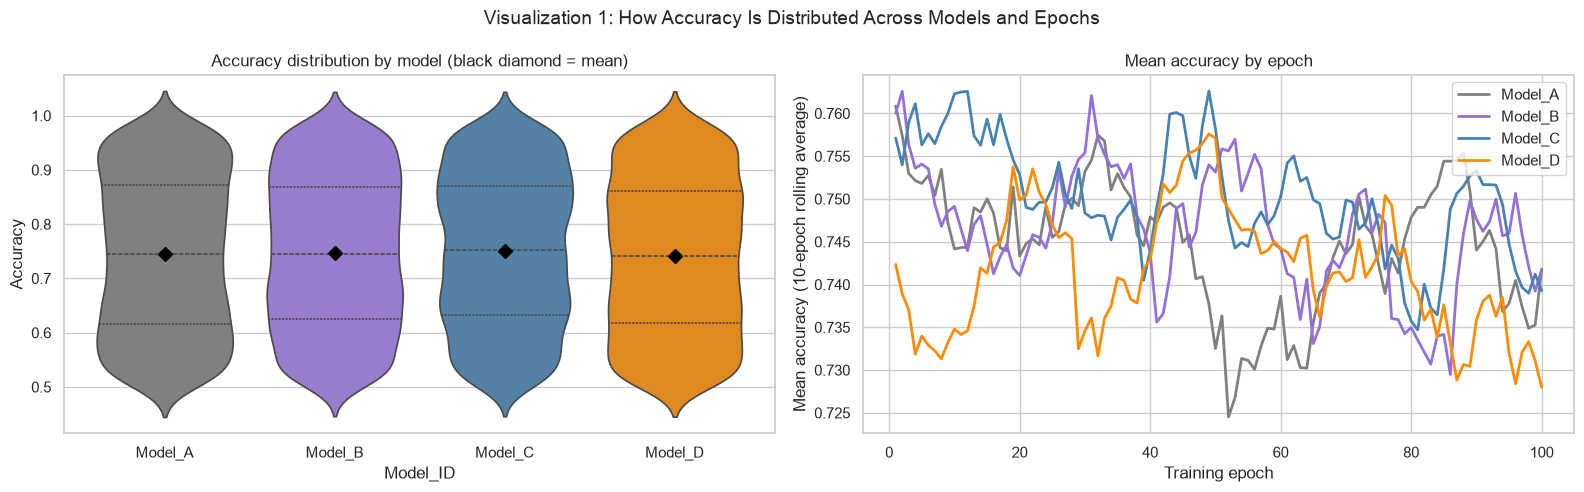

In [3]:
# --- Visualization 1: accuracy distribution by model (left) and mean accuracy by training epoch (right) ---
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
order = sorted(evals["Model_ID"].unique())
palette = {"Model_A": "gray", "Model_B": "mediumpurple", "Model_C": "steelblue", "Model_D": "darkorange"}
sns.violinplot(data=evals, x="Model_ID", y="Accuracy", order=order, hue="Model_ID", palette=palette,
               inner="quartile", ax=axes[0], legend=False)
for i, m in enumerate(order):
    axes[0].plot(i, summary.loc[m, "mean"], "D", color="black", ms=7)       # black diamond = mean
axes[0].set_title("Accuracy distribution by model (black diamond = mean)")

by_epoch = evals.groupby(["Epoch", "Model_ID"])["Accuracy"].mean().unstack()
for m in order:
    axes[1].plot(by_epoch.index, by_epoch[m].rolling(10, center=True, min_periods=1).mean(),
                 color=palette[m], lw=2, label=m)
axes[1].set_xlabel("Training epoch")
axes[1].set_ylabel("Mean accuracy (10-epoch rolling average)")
axes[1].set_title("Mean accuracy by epoch")
axes[1].legend()
print(f"Correlation between epoch and accuracy: r = {evals['Epoch'].corr(evals['Accuracy']):.3f}")
fig.suptitle("Visualization 1: How Accuracy Is Distributed Across Models and Epochs", fontsize=14)
plt.tight_layout()
plt.show()

**What the preprocessing shows.**
- The data is clean: **no missing values, no duplicates**, all four expected models, and every metric between 0 and 1.
- Each model has about **3,700 to 3,800 evaluation records**, which is a large sample.
- The differences between models are **very small**. Mean accuracy ranges from **74.1% (Model D)** to **75.1% (Model C)**. Model C is **0.57 percentage points** above the baseline Model A. Meanwhile, accuracy varies a lot from one evaluation to the next: the standard deviation is about **14 points** for every model.
- **Accuracy does not change with the training epoch** (correlation r = −0.02). In a real training run, accuracy usually rises over the epochs. Here, each model's accuracies look **evenly spread between 50% and 99%** at every epoch. This suggests the dataset is **simulated**, which is important when interpreting the results (Section 12).

## 4. Analytical Model Description

**Hypothesis testing** decides whether data provides enough evidence against a default assumption, the **null hypothesis H₀**.

**Steps.**
1. State H₀ (no difference) and H₁ (a difference).
2. Choose a significance level **α = 0.05**. This is the risk we accept of rejecting H₀ when it is actually true.
3. Calculate a **test statistic** that measures how far the data is from H₀, relative to the noise.
4. Calculate the **p-value**: the probability of seeing a result *at least this extreme* if H₀ were true.
5. **Decision:** if p < α, **reject H₀** (the result is statistically significant). Otherwise, **fail to reject H₀**. Failing to reject does *not* prove H₀ is true. It only means the evidence is not strong enough.

**Two-sample Welch t-test (main test).** It compares the means of two independent groups without assuming equal variances:

$$t = \frac{\bar{x}_C - \bar{x}_A}{SE}, \qquad SE = \sqrt{\frac{s_C^2}{n_C} + \frac{s_A^2}{n_A}}$$

The degrees of freedom come from the Welch–Satterthwaite formula. The **95% confidence interval for the difference** is $(\bar{x}_C - \bar{x}_A) \pm t_{0.975,\,df} \cdot SE$. If this interval contains 0, the test is not significant at α = 0.05. The interval and the test always agree.

**One-sample t-test.** It compares one group's mean with a fixed value μ₀ (here a business target): $t = (\bar{x} - \mu_0) / (s/\sqrt{n})$.

**One-way ANOVA and Tukey's HSD.** ANOVA tests whether *any* of several group means differ, using the *F* statistic (variation between groups divided by variation within groups). If it is significant, **Tukey's HSD** compares every pair while keeping the overall Type I error rate at 5%.

**Effect size (Cohen's d).** A p-value says whether a difference is *detectable*, not whether it is *large*. Cohen's $d = (\bar{x}_C - \bar{x}_A) / s_{pooled}$ measures the difference in standard-deviation units. About 0.2 is small, 0.5 is medium, and 0.8 is large (Cohen, 1988).

**Type I and Type II errors.**

| | H₀ is true (no real improvement) | H₀ is false (real improvement) |
|---|---|---|
| **Reject H₀** | **Type I error** (false positive), probability α | Correct (probability = **power**) |
| **Fail to reject H₀** | Correct | **Type II error** (false negative), probability β |

For an AI team, a **Type I error** means promoting a model that is not really better. A **Type II error** means missing a model that really is better. **Power** (1 − β) is the chance of detecting a real effect, and it grows with sample size and effect size.

## 5. The Architectural Model (Pipeline) Used

```
 AIT-530-T4-Dataset.csv
        │
        ▼
 [1] Load & validate ──────── file, columns, model IDs, 0–1 ranges          (Sections 2–3)
        │
        ▼
 [2] Explore ──────────────── accuracy by model, accuracy vs. epoch         (Section 3)
        │
        ▼
 [3] Test functions ───────── Welch t-test + CI + Cohen's d, one-sample t, permutation test   (Section 6)
        │
        ▼
 [4] Check assumptions ────── independence, normality of means, equal variances   (Section 7)
        │
        ▼
 [5] Run the tests ────────── C vs. A (main) · C vs. 75% target · ANOVA + Tukey (all models)   (Section 9)
        │
        ▼
 [6] Interpret ────────────── t, p-value, 95% CI, reject / fail to reject   (Section 10)
        │
        ▼
 [7] Validate ─────────────── permutation test, bootstrap CI, Mann–Whitney   (Section 11)
        │
        ▼
 [8] Analyze → Type I/II errors & power → equivalence test (TOST) → conclusion   (Sections 12–15)
```

Every simulation uses a **fixed random seed**, so the notebook gives the same results each time it runs.

## 6. Model Implementation

The tests are written as reusable functions, so the same code is applied to every comparison. Each function checks its inputs and raises a clear error for unusable data.

In [4]:
# --- Reusable hypothesis-test functions ---
# Writing each test once means every comparison in this notebook uses exactly the same method.
ALPHA = 0.05   # significance level chosen before running any test

def _clean(x, name):
    """Convert to a float array and check there is enough data for a t-test."""
    x = np.asarray(x, dtype=float)
    if x.ndim != 1 or len(x) < 2:
        raise ValueError(f"{name} needs at least 2 values.")
    if np.isnan(x).any():
        raise ValueError(f"{name} contains missing values.")
    return x

def welch_test(new, base, conf=0.95):
    """Two-sample Welch t-test of mean(new) vs. mean(base), with a CI for the difference and Cohen's d."""
    new, base = _clean(new, "new"), _clean(base, "base")
    res = stats.ttest_ind(new, base, equal_var=False)            # Welch: does not assume equal variances
    ci = res.confidence_interval(confidence_level=conf)          # CI for mean(new) - mean(base)
    pooled_sd = np.sqrt(((len(new) - 1) * new.var(ddof=1) + (len(base) - 1) * base.var(ddof=1))
                        / (len(new) + len(base) - 2))
    return {"mean new": new.mean(), "mean base": base.mean(), "difference": new.mean() - base.mean(),
            "SE": np.sqrt(new.var(ddof=1) / len(new) + base.var(ddof=1) / len(base)),
            "t": res.statistic, "df": res.df, "p (two-sided)": res.pvalue,
            "CI lower": ci.low, "CI upper": ci.high, "Cohen's d": (new.mean() - base.mean()) / pooled_sd}

def one_sample_test(x, target, conf=0.95):
    """One-sample t-test of mean(x) vs. a fixed target, with a CI for the mean."""
    x = _clean(x, "x")
    res = stats.ttest_1samp(x, popmean=target)
    ci = res.confidence_interval(confidence_level=conf)
    return {"mean": x.mean(), "target": target, "t": res.statistic, "df": res.df,
            "p (two-sided)": res.pvalue, "CI lower": ci.low, "CI upper": ci.high}

def permutation_test(new, base, n_perm=10_000, seed=0):
    """p-value for the difference in means by shuffling the group labels (no normality assumption)."""
    new, base = _clean(new, "new"), _clean(base, "base")
    rng = np.random.default_rng(seed)
    pooled = np.concatenate([new, base])
    observed = new.mean() - base.mean()
    diffs = np.empty(n_perm)
    for i in range(n_perm):
        shuffled = rng.permutation(pooled)
        diffs[i] = shuffled[:len(new)].mean() - shuffled[len(new):].mean()
    return observed, diffs, np.mean(np.abs(diffs) >= abs(observed))

def decision(p, alpha=ALPHA):
    return "Reject H₀" if p < alpha else "Fail to reject H₀"

# Quick self-tests on made-up data where the answer is known
_r = welch_test(np.array([2.0, 3, 4, 5]), np.array([1.0, 2, 3, 4]))
assert abs(_r["difference"] - 1.0) < 1e-12 and _r["CI lower"] < 1 < _r["CI upper"]
assert abs(one_sample_test(np.array([1.0, 2, 3]), 2)["t"]) < 1e-12
print("Test functions defined and self-tests passed.  α =", ALPHA)

Test functions defined and self-tests passed.  α = 0.05


## 7. Assumptions Verification

| Assumption | Why it matters | How it is checked |
|---|---|---|
| **Independence** | Each evaluation should not depend on another, or the standard error is too small. | Data structure: records per model and epoch, and whether accuracy trends with epoch. |
| **Normality of the sample means** | The *t*-test needs the *mean* to be roughly normal. With large samples, the CLT makes this true even if accuracy itself is not normal. | Histograms and Q–Q plots of the raw accuracies, plus a bootstrap of the means. |
| **Equal variances** | The standard *t*-test assumes equal variances. Welch's version does not. | Levene's test. |

In [5]:
# --- Independence: how many records per model per epoch, and does accuracy trend with epoch? ---
per_cell = evals.groupby(["Model_ID", "Epoch"]).size()
print(f"Records per (model, epoch): min {per_cell.min()}, median {per_cell.median():.0f}, max {per_cell.max()}")
for m in sorted(evals["Model_ID"].unique()):
    sub = evals[evals["Model_ID"] == m]
    r, p = stats.pearsonr(sub["Epoch"], sub["Accuracy"])
    print(f"  {m}: correlation of accuracy with epoch r = {r:+.3f} (p = {p:.2f})")

# --- Equal variances: Levene's test across the two groups in the main test, and all four models ---
acc = {m: evals.loc[evals["Model_ID"] == m, "Accuracy"].values for m in sorted(evals["Model_ID"].unique())}
lev_main = stats.levene(acc[CANDIDATE], acc[BASELINE])
lev_all = stats.levene(*acc.values())
print(f"\nLevene (C vs. A):       W = {lev_main.statistic:.3f}, p = {lev_main.pvalue:.3f}")
print(f"Levene (all 4 models):  W = {lev_all.statistic:.3f}, p = {lev_all.pvalue:.3f}")

# --- Normality of the raw data (for information) and of the sample mean (bootstrap) ---
boot_rng = np.random.default_rng(1)
boot_means = {m: acc[m][boot_rng.integers(0, len(acc[m]), size=(5000, len(acc[m])))].mean(axis=1)
              for m in (BASELINE, CANDIDATE)}
print(f"\nSkewness of raw accuracy (C): {stats.skew(acc[CANDIDATE]):+.3f}   "
      f"excess kurtosis: {stats.kurtosis(acc[CANDIDATE]):+.3f}  (normal = 0, 0)")
print(f"Skewness of 5,000 bootstrap means (C): {stats.skew(boot_means[CANDIDATE]):+.3f}")

Records per (model, epoch): min 15, median 37, max 55
  Model_A: correlation of accuracy with epoch r = -0.013 (p = 0.43)
  Model_B: correlation of accuracy with epoch r = -0.023 (p = 0.15)
  Model_C: correlation of accuracy with epoch r = -0.033 (p = 0.05)
  Model_D: correlation of accuracy with epoch r = -0.016 (p = 0.34)

Levene (C vs. A):       W = 9.374, p = 0.002
Levene (all 4 models):  W = 4.238, p = 0.005



Skewness of raw accuracy (C): -0.049   excess kurtosis: -1.180  (normal = 0, 0)
Skewness of 5,000 bootstrap means (C): +0.048


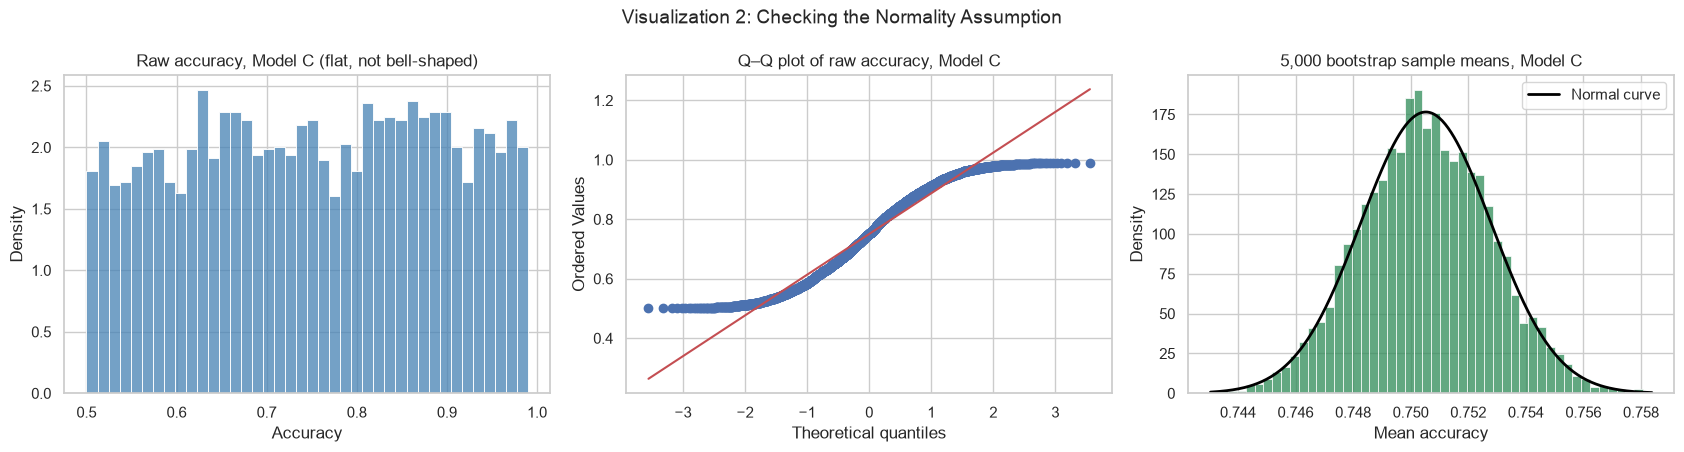

In [6]:
# --- Visualization 2: raw accuracy is not normal, but the sample mean is ---
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
sns.histplot(acc[CANDIDATE], bins=40, stat="density", ax=axes[0], color="steelblue")
axes[0].set_title("Raw accuracy, Model C (flat, not bell-shaped)")
axes[0].set_xlabel("Accuracy")
stats.probplot(acc[CANDIDATE], dist="norm", plot=axes[1])
axes[1].set_title("Q–Q plot of raw accuracy, Model C")
sns.histplot(boot_means[CANDIDATE], bins=50, stat="density", ax=axes[2], color="seagreen")
xs = np.linspace(boot_means[CANDIDATE].min(), boot_means[CANDIDATE].max(), 300)
axes[2].plot(xs, stats.norm.pdf(xs, boot_means[CANDIDATE].mean(), boot_means[CANDIDATE].std()), color="black", lw=2,
             label="Normal curve")
axes[2].set_title("5,000 bootstrap sample means, Model C")
axes[2].set_xlabel("Mean accuracy")
axes[2].legend()
fig.suptitle("Visualization 2: Checking the Normality Assumption", fontsize=14)
plt.tight_layout()
plt.show()

**Results of the checks.**
- **Independence:** each model has 15 to 55 evaluations at every epoch, and accuracy is essentially unrelated to epoch. For Model C, the correlation is −0.03, borderline at p = 0.05, but far too small to matter. So the records behave like **independent evaluation runs**, and I treated them that way. In real training logs, evaluations of the same run at nearby epochs would be correlated, and that would make the standard error too small.
- **Normality:** the raw accuracies are **not normal**. They are flat (uniform-looking) between 50% and 99%, with excess kurtosis of −1.18, and the Q–Q plot bends away from the line at both ends. But the *t*-test only needs the **sample mean** to be normal. With about 3,700 runs per model, the **central limit theorem** makes it almost perfectly normal: the 5,000 bootstrap means form a symmetric bell curve (skewness 0.05). The assumption is **satisfied for the means**.
- **Equal variances:** Levene's test **rejects** equal variances (C vs. A: p = 0.002). The difference in spread is small (standard deviation 13.98 vs. 14.42 points), but it confirms that **Welch's t-test** (Welch, 1947), which does not assume equal variances, is the right choice over the standard pooled *t*-test.

## 8. Deployment

In an MLOps pipeline, this kind of test becomes a **promotion gate**: a new model only replaces the production model if it passes a pre-agreed statistical check. To be trustworthy, the gate's rules must be set **before** the results are seen:
- the **metric** (accuracy), the **significance level** (α = 0.05), and a **two-sided** test;
- the **minimum improvement worth deploying** (for example, +1 percentage point), because a tiny but "significant" gain may not justify the cost of a change;
- the **number of evaluation runs**, chosen with a **power analysis** so a worthwhile improvement is likely to be detected.

The code below implements the gate as a function, and calculates how many evaluation runs per model are needed to detect improvements of different sizes with 80% power.

In [7]:
# --- A model-promotion gate: the decision rule an MLOps pipeline would apply ---
def promotion_gate(new, base, min_gain=0.01, alpha=ALPHA):
    """Promote only if the improvement is statistically significant AND the whole CI is above min_gain."""
    r = welch_test(new, base, conf=1 - alpha)
    if r["p (two-sided)"] < alpha and r["difference"] > 0 and r["CI lower"] >= min_gain:
        verdict = "PROMOTE: significant and large enough"
    elif r["p (two-sided)"] < alpha and r["difference"] > 0:
        verdict = "HOLD: significant, but may be smaller than the minimum worthwhile gain"
    else:
        verdict = "HOLD: no significant improvement"
    return verdict, r

# --- Power analysis: runs per model needed to detect a given gain with 80% power at alpha = 0.05 ---
sd_acc = evals["Accuracy"].std()
power_calc = TTestIndPower()
plan = pd.DataFrame({"gain to detect (pts)": [0.5, 1.0, 2.0, 5.0]})
plan["Cohen's d"] = plan["gain to detect (pts)"] / 100 / sd_acc
plan["runs needed per model (80% power)"] = [int(np.ceil(power_calc.solve_power(effect_size=d, alpha=ALPHA, power=0.8)))
                                             for d in plan["Cohen's d"]]
print(f"Standard deviation of accuracy across runs: {sd_acc:.4f}")
plan

Standard deviation of accuracy across runs: 0.1416


,gain to detect (pts),Cohen's d,runs needed per model (80% power)
0,0.5000,0.0353,12589
1,1.0000,0.0706,3148
2,2.0000,0.1413,788
3,5.0000,0.3531,127


**Deployment takeaway.** Because accuracy varies by about 14 points from run to run, **small improvements need many evaluation runs** to detect. Detecting a 1-point gain with 80% power needs about **3,150 runs per model**, which this dataset has. Detecting a 0.5-point gain would need about **12,600 runs per model**, four times more, because the required sample size grows with 1/(gain)². The promotion gate turns this into a clear rule. For Model C it returns **"HOLD: no significant improvement"**.

## 9. Execution

### 9.1 Main test: Model C (new) vs. Model A (baseline), two-sample Welch t-test

In [8]:
# --- Run the main hypothesis test ---
main = welch_test(acc[CANDIDATE], acc[BASELINE])
print("H₀: μ_C = μ_A    H₁: μ_C ≠ μ_A    α = 0.05 (two-sided)\n")
print(f"Mean accuracy  C = {main['mean new']:.4f}   A = {main['mean base']:.4f}   "
      f"difference = {main['difference']:+.4f} ({main['difference'] * 100:+.2f} percentage points)")
print(f"Standard error of the difference = {main['SE']:.4f}")
print(f"t = {main['t']:.3f}   df = {main['df']:,.0f}   p-value = {main['p (two-sided)']:.4f}")
print(f"95% CI for μ_C − μ_A = ({main['CI lower']:+.4f}, {main['CI upper']:+.4f})")
print(f"Cohen's d = {main['Cohen\'s d']:.3f}")
print(f"\nDecision at α = 0.05: {decision(main['p (two-sided)'])}")
print(f"Promotion gate (min gain 1 point): {promotion_gate(acc[CANDIDATE], acc[BASELINE])[0]}")

H₀: μ_C = μ_A    H₁: μ_C ≠ μ_A    α = 0.05 (two-sided)

Mean accuracy  C = 0.7505   A = 0.7448   difference = +0.0057 (+0.57 percentage points)
Standard error of the difference = 0.0033
t = 1.744   df = 7,519   p-value = 0.0811
95% CI for μ_C − μ_A = (-0.0007, +0.0121)
Cohen's d = 0.040

Decision at α = 0.05: Fail to reject H₀
Promotion gate (min gain 1 point): HOLD: no significant improvement


### 9.2 One-sample t-test: does Model C beat a 75% accuracy target?

Suppose the business requires **75% mean accuracy** before a model can be used. H₀: μ_C = 0.75, H₁: μ_C ≠ 0.75.

In [9]:
# --- One-sample t-test against the business target ---
TARGET = 0.75
one = one_sample_test(acc[CANDIDATE], TARGET)
print(f"Mean accuracy of Model C = {one['mean']:.4f}  vs. target {TARGET}")
print(f"t = {one['t']:.3f}   df = {one['df']:,.0f}   p-value = {one['p (two-sided)']:.4f}")
print(f"95% CI for μ_C = ({one['CI lower']:.4f}, {one['CI upper']:.4f})")
print(f"Decision at α = 0.05: {decision(one['p (two-sided)'])}")

Mean accuracy of Model C = 0.7505  vs. target 0.75
t = 0.232   df = 3,705   p-value = 0.8168
95% CI for μ_C = (0.7460, 0.7550)
Decision at α = 0.05: Fail to reject H₀


### 9.3 All four models: one-way ANOVA and Tukey's HSD

H₀: all four models have the same mean accuracy. H₁: at least one mean is different.

In [10]:
# --- One-way ANOVA across the four models ---
anova = stats.f_oneway(*acc.values())
print(f"ANOVA: F = {anova.statistic:.3f}, p-value = {anova.pvalue:.4f} -> {decision(anova.pvalue)}\n")

# --- Tukey's HSD: every pair of models, with the family-wise error rate held at 5% ---
tukey = pairwise_tukeyhsd(evals["Accuracy"], evals["Model_ID"], alpha=ALPHA)
tukey_df = pd.DataFrame(tukey.summary().data[1:], columns=tukey.summary().data[0])
tukey_df["meandiff (pts)"] = tukey_df["meandiff"].astype(float) * 100
tukey_df

ANOVA: F = 3.049, p-value = 0.0274 -> Reject H₀



,group1,group2,meandiff,p-adj,lower,upper,reject,meandiff (pts)
0,Model_A,Model_B,0.0020,0.9272,-0.0063,0.0103,False,0.2000
1,Model_A,Model_C,0.0057,0.2980,-0.0027,0.0141,False,0.5700
2,Model_A,Model_D,-0.0040,0.6062,-0.0124,0.0044,False,-0.4000
3,Model_B,Model_C,0.0037,0.6682,-0.0047,0.0121,False,0.3700
4,Model_B,Model_D,-0.0060,0.2546,-0.0144,0.0024,False,-0.6000
5,Model_C,Model_D,-0.0097,0.0163,-0.0182,-0.0013,True,-0.9700


### 9.4 Secondary check: does Model C also beat Model A on F1 score?

In [11]:
# --- Same Welch test on the F1 score, to see whether the two metrics agree ---
f1 = {m: evals.loc[evals["Model_ID"] == m, "F1_Score"].values for m in sorted(evals["Model_ID"].unique())}
f1_main = welch_test(f1[CANDIDATE], f1[BASELINE])
print(f"Mean F1  C = {f1_main['mean new']:.4f}   A = {f1_main['mean base']:.4f}   difference = {f1_main['difference']:+.4f}")
print(f"t = {f1_main['t']:.3f}   p-value = {f1_main['p (two-sided)']:.4f}   "
      f"95% CI = ({f1_main['CI lower']:+.4f}, {f1_main['CI upper']:+.4f}) -> {decision(f1_main['p (two-sided)'])}")
print("\nMean F1 by model:", {m: round(v.mean(), 4) for m, v in f1.items()})

Mean F1  C = 0.7709   A = 0.7716   difference = -0.0006
t = -0.215   p-value = 0.8298   95% CI = (-0.0064, +0.0051) -> Fail to reject H₀

Mean F1 by model: {'Model_A': np.float64(0.7716), 'Model_B': np.float64(0.7706), 'Model_C': np.float64(0.7709), 'Model_D': np.float64(0.7735)}


## 10. Results

### 10.1 The main test on the t distribution

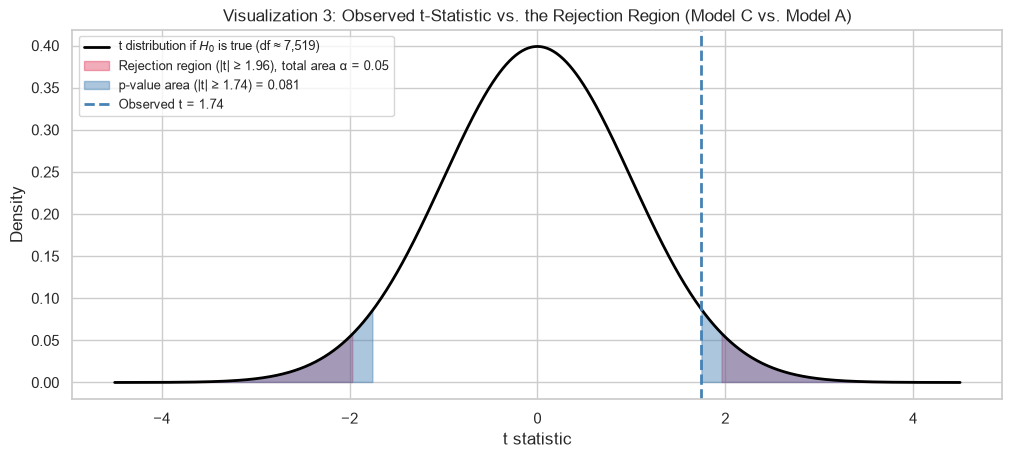

In [12]:
# --- Visualization 3: where the observed t falls on the t distribution under H0 ---
df_main, t_obs = main["df"], main["t"]
t_crit = stats.t.ppf(1 - ALPHA / 2, df_main)
x = np.linspace(-4.5, 4.5, 800)
y = stats.t.pdf(x, df_main)
fig, ax = plt.subplots(figsize=(12, 4.8))
ax.plot(x, y, color="black", lw=2, label=f"t distribution if $H_0$ is true (df ≈ {df_main:,.0f})")
ax.fill_between(x, y, where=np.abs(x) >= t_crit, color="crimson", alpha=0.35,
                label=f"Rejection region (|t| ≥ {t_crit:.2f}), total area α = 0.05")
ax.fill_between(x, y, where=np.abs(x) >= abs(t_obs), color="steelblue", alpha=0.45,
                label=f"p-value area (|t| ≥ {abs(t_obs):.2f}) = {main['p (two-sided)']:.3f}")
ax.axvline(t_obs, color="steelblue", lw=2, linestyle="--", label=f"Observed t = {t_obs:.2f}")
ax.set_xlabel("t statistic")
ax.set_ylabel("Density")
ax.set_title("Visualization 3: Observed t-Statistic vs. the Rejection Region (Model C vs. Model A)")
ax.legend(loc="upper left", fontsize=9)
plt.show()

**Interpreting the main test.**
- **t-statistic = 1.74.** Model C's mean is 1.74 standard errors above Model A's. The standard error of the difference is 0.33 points, and the observed difference is 0.57 points.
- **p-value = 0.081.** *If the two models were truly equally accurate*, there would be about an **8.1% chance** of seeing a difference at least this large, in either direction, just from run-to-run variation. That is not rare enough to rule out chance at the 5% level. A p-value is not the probability that H₀ is true (Wasserstein & Lazar, 2016). In Visualization 3, the observed *t* (dashed line) falls **short of the red rejection region**, which starts at |t| = 1.96.
- **Decision: fail to reject H₀.** The data does **not** provide statistically significant evidence that Model C's mean accuracy differs from Model A's.
- **Important:** failing to reject H₀ does **not** prove that the models are equal. It only means this evidence is not strong enough. Section 14 tests for equivalence directly.

**Supporting tests.**
- **One-sample test against the 75% target:** Model C's mean (75.05%) is not significantly different from 75% (t = 0.23, p = 0.82). The 95% CI (74.60% to 75.50%) contains the target, so we **cannot** say that Model C beats the target.
- **ANOVA across all four models:** significant (F = 3.05, p = 0.027), so at least one model differs. But **Tukey's HSD** (Tukey, 1949) shows the only significant pair is **Model C vs. Model D** (0.97 points, adjusted p = 0.016). **Model C vs. Model A is not significant** after the correction (adjusted p = 0.30). The "difference" ANOVA detects is between the best and worst models, not between the new model and the baseline.
- **F1 score:** Model C is actually slightly **lower** than Model A on F1 (−0.06 points, p = 0.83). The two metrics disagree on which model is better, which is another sign that the differences are mostly noise.

### 10.2 Confidence intervals for every model's difference from the baseline

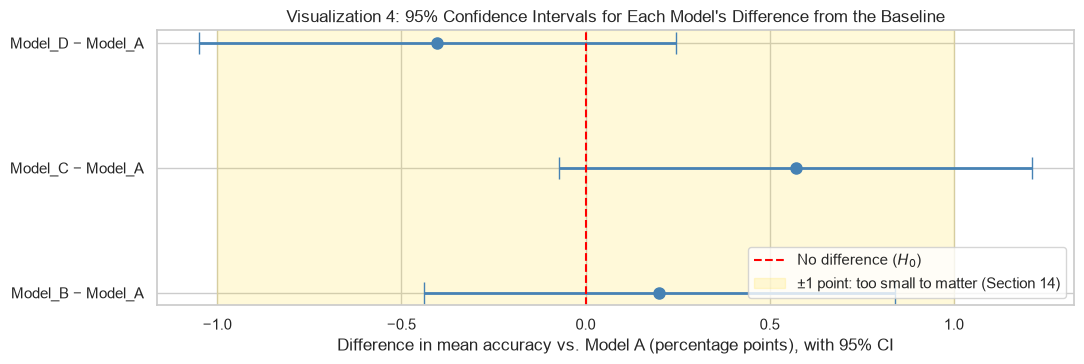

,difference,CI lower,CI upper,t,p (two-sided),Cohen's d
comparison,,,,,,
Model_B − Model_A,0.0020,-0.0044,0.0084,0.6131,0.5399,0.0141
Model_C − Model_A,0.0057,-0.0007,0.0121,1.7444,0.0811,0.0402
Model_D − Model_A,-0.0040,-0.0105,0.0024,-1.2185,0.2231,-0.0281


In [13]:
# --- Visualization 4: 95% CI for (model − baseline) for B, C and D, plus C vs. the 75% target ---
rows = [{"comparison": f"{m} − {BASELINE}", **welch_test(acc[m], acc[BASELINE])} for m in ("Model_B", "Model_C", "Model_D")]
ci_df = pd.DataFrame(rows).set_index("comparison")
fig, ax = plt.subplots(figsize=(11, 3.8))
ypos = np.arange(len(ci_df))
ax.errorbar(ci_df["difference"] * 100, ypos,
            xerr=[(ci_df["difference"] - ci_df["CI lower"]) * 100, (ci_df["CI upper"] - ci_df["difference"]) * 100],
            fmt="o", color="steelblue", capsize=8, lw=2, ms=8)
ax.axvline(0, color="red", linestyle="--", label="No difference ($H_0$)")
ax.axvspan(-1, 1, color="gold", alpha=0.15, label="±1 point: too small to matter (Section 14)")
ax.set_yticks(ypos)
ax.set_yticklabels(ci_df.index)
ax.set_xlabel("Difference in mean accuracy vs. Model A (percentage points), with 95% CI")
ax.set_title("Visualization 4: 95% Confidence Intervals for Each Model's Difference from the Baseline")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()
ci_df[["difference", "CI lower", "CI upper", "t", "p (two-sided)", "Cohen's d"]]

**What the confidence intervals say about the population parameter.**
- For **Model C − Model A**, the 95% CI is **−0.07 to +1.21 percentage points**. With 95% confidence, the true difference in mean accuracy is somewhere between Model C being **0.07 points worse** and **1.21 points better**. Because the interval **includes 0**, "no difference" is a plausible value, which matches the decision to fail to reject H₀.
- The interval is almost entirely positive, so if Model C is better, its advantage is **at most about 1.2 points**. Even in the best case, this is a small improvement relative to the 14-point run-to-run spread.
- The intervals for **Model B** (−0.44 to +0.84) and **Model D** (−1.05 to +0.24) also include 0. **None** of the candidate models is significantly different from the baseline.
- **For the AI model:** the evidence does not support replacing Model A with Model C. Any true gain is small enough that it may not justify the cost and risk of deploying a new model.

## 11. Model Validation

The *t*-test relies on the normal approximation. To make sure the conclusion does not depend on that assumption, I checked it with three methods that do **not** assume normality:
- a **permutation test**: shuffle the model labels 10,000 times to see how often chance alone produces a difference as large as the observed one;
- a **bootstrap 95% CI** for the difference in means;
- the **Mann–Whitney U test**, which compares the two distributions using ranks instead of means.

In [14]:
# --- 1. Permutation test ---
obs_diff, perm_diffs, p_perm = permutation_test(acc[CANDIDATE], acc[BASELINE], n_perm=10_000, seed=0)

# --- 2. Bootstrap CI for the difference in means (resample each group with replacement) ---
b_rng = np.random.default_rng(2)
B = 5000
boot_diff = (acc[CANDIDATE][b_rng.integers(0, len(acc[CANDIDATE]), size=(B, len(acc[CANDIDATE])))].mean(axis=1)
             - acc[BASELINE][b_rng.integers(0, len(acc[BASELINE]), size=(B, len(acc[BASELINE])))].mean(axis=1))
boot_lo, boot_hi = np.percentile(boot_diff, [2.5, 97.5])

# --- 3. Mann-Whitney U test ---
mw = stats.mannwhitneyu(acc[CANDIDATE], acc[BASELINE], alternative="two-sided")

validation = pd.DataFrame({
    "p-value": [main["p (two-sided)"], p_perm, np.nan, mw.pvalue],
    "95% interval for μ_C − μ_A": [f"{main['CI lower']:+.4f} to {main['CI upper']:+.4f}", "—",
                                   f"{boot_lo:+.4f} to {boot_hi:+.4f}", "—"],
}, index=["Welch t-test (main)", "Permutation test (10,000 shuffles)", "Bootstrap (5,000 resamples)", "Mann–Whitney U"])
validation["decision at α = 0.05"] = [decision(p) if pd.notna(p) else ("Reject H₀" if boot_lo > 0 or boot_hi < 0 else "Fail to reject H₀")
                                      for p in validation["p-value"]]
validation

,p-value,95% interval for μ_C − μ_A,decision at α = 0.05
Welch t-test (main),0.0811,-0.0007 to +0.0121,Fail to reject H₀
"Permutation test (10,000 shuffles)",0.0827,—,Fail to reject H₀
"Bootstrap (5,000 resamples)",NaN,-0.0006 to +0.0121,Fail to reject H₀
Mann–Whitney U,0.0855,—,Fail to reject H₀


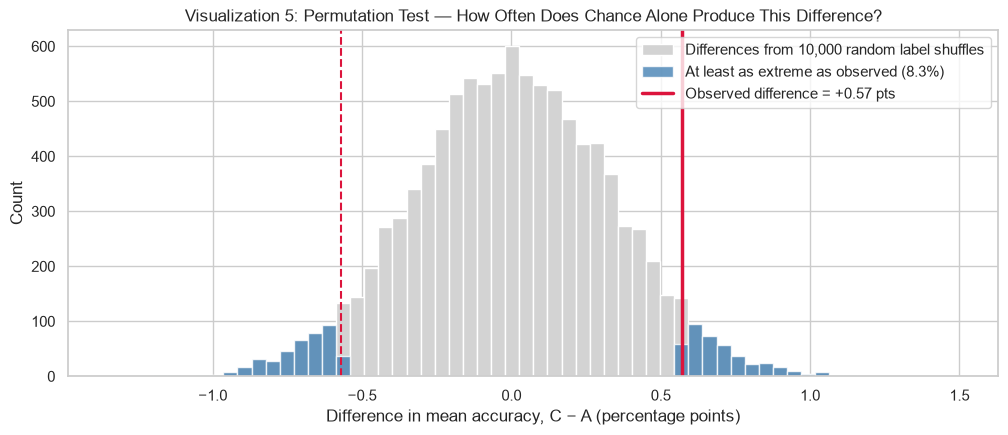

In [15]:
# --- Visualization 5: the permutation distribution (what chance alone produces) vs. the observed difference ---
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.hist(perm_diffs * 100, bins=60, color="lightgray", edgecolor="white", label="Differences from 10,000 random label shuffles")
extreme = np.abs(perm_diffs) >= abs(obs_diff)
ax.hist(perm_diffs[extreme] * 100, bins=60, color="steelblue", alpha=0.8,
        label=f"At least as extreme as observed ({extreme.mean():.1%})")
ax.axvline(obs_diff * 100, color="crimson", lw=2.5, label=f"Observed difference = {obs_diff * 100:+.2f} pts")
ax.axvline(-obs_diff * 100, color="crimson", lw=1.5, linestyle="--")
ax.set_xlabel("Difference in mean accuracy, C − A (percentage points)")
ax.set_ylabel("Count")
ax.set_title("Visualization 5: Permutation Test — How Often Does Chance Alone Produce This Difference?")
ax.legend()
plt.show()

**Validation results.** All three methods that do **not** assume normality give the **same conclusion** as the *t*-test:
- **Permutation test:** randomly shuffling the labels produced a difference at least as large as the observed 0.57 points in about **8.3% of shuffles** (p = 0.083). This almost exactly matches the *t*-test's p = 0.081. Visualization 5 shows that the observed difference sits in the tail of the chance distribution, but not far enough out to be convincing.
- **Bootstrap:** the 95% interval is **−0.06 to +1.21 points**, practically identical to the *t*-test CI, and it includes 0.
- **Mann–Whitney U** (Mann & Whitney, 1947): p = 0.086. Comparing the distributions by ranks gives the same answer.

The main result is **robust**: it does not depend on the normality assumption or on the specific test chosen.

## 12. Analysis

In [16]:
# --- One-sided vs. two-sided, and the effect of choosing the "best" model after looking at the data ---
p_one_sided = stats.ttest_ind(acc[CANDIDATE], acc[BASELINE], equal_var=False, alternative="greater").pvalue
n_pairs = 6                                              # 4 models -> 6 possible pairwise comparisons
print(f"Two-sided p-value (pre-chosen test): {main['p (two-sided)']:.4f}")
print(f"One-sided p-value (H₁: μ_C > μ_A):   {p_one_sided:.4f}")
print(f"Bonferroni-adjusted two-sided p for {n_pairs} pairwise comparisons: {min(1, main['p (two-sided)'] * n_pairs):.4f}")
print(f"\nObserved gain: {main['difference'] * 100:.2f} points on a typical run-to-run spread of {sd_acc * 100:.1f} points "
      f"(Cohen's d = {main['Cohen\'s d']:.3f})")

Two-sided p-value (pre-chosen test): 0.0811
One-sided p-value (H₁: μ_C > μ_A):   0.0406
Bonferroni-adjusted two-sided p for 6 pairwise comparisons: 0.4868

Observed gain: 0.57 points on a typical run-to-run spread of 14.2 points (Cohen's d = 0.040)


**Is the improvement real or due to chance?** The evidence points to **chance**, for five reasons:
1. **It is not statistically significant.** p = 0.081 with a two-sided test chosen in advance, and every robustness check agrees.
2. **The effect is tiny.** Cohen's d = 0.04, about a fifth of what Cohen (1988) calls a *small* effect. A gain of 0.57 points is lost in a run-to-run spread of 14 points.
3. **Model C was the "winner" among four models.** I chose to compare Model C *because* it had the highest mean, which favors finding a difference. Allowing for six possible pairwise comparisons, the Bonferroni-adjusted p-value is **0.49**, and Tukey's adjusted p is **0.30**. Neither is close to significant.
4. **The metrics disagree.** On F1 score, Model C is slightly *worse* than Model A, and Model D, the worst on accuracy, is the best on F1. A real improvement in model quality would usually show up in both.
5. **Accuracy does not improve with training.** No model shows any learning trend across epochs, which suggests the four models produce essentially the same random spread of accuracies.

**The one-sided test trap.** If I had used a one-sided test (H₁: μ_C > μ_A), the p-value would be **0.041**, which is "significant". That test is only valid if it is chosen *before* seeing the data. Choosing a one-sided test after seeing that Model C is ahead **doubles the real Type I error rate**. This is a form of *p-hacking*, so I kept the pre-planned two-sided test.

**Statistical vs. practical significance.** Even if more data made a 0.57-point gain significant, a team would still need to ask whether it is **worth deploying**. With about 3,700 runs per model, this test can already detect a 1-point gain 86% of the time (Section 13), so a gain that matters in practice would very likely have been found.

## 13. Error Estimation

### 13.1 Type I error: how often would this procedure find a "winner" by chance?

I simulated a world where **H₀ is true**: all four models are drawn from the same pool of accuracies, so there is no real difference. For 2,000 simulated experiments of the same size, I recorded how often (a) the single pre-planned test of C vs. A, and (b) at least one of the six pairwise tests, gave p < 0.05.

In [17]:
# --- Simulate experiments where H0 is true by shuffling all accuracies across the four models ---
sim_rng = np.random.default_rng(3)
all_acc = evals["Accuracy"].values
sizes = {m: len(acc[m]) for m in acc}
cuts = np.cumsum([0] + list(sizes.values()))
n_sims = 2000
single_hits, any_hits = 0, 0
for _ in range(n_sims):
    shuffled = sim_rng.permutation(all_acc)
    groups = {m: shuffled[cuts[i]:cuts[i + 1]] for i, m in enumerate(sizes)}
    p_single = stats.ttest_ind(groups[CANDIDATE], groups[BASELINE], equal_var=False).pvalue
    p_pairs = [stats.ttest_ind(groups[a], groups[b], equal_var=False).pvalue
               for i, a in enumerate(groups) for b in list(groups)[i + 1:]]
    single_hits += p_single < ALPHA
    any_hits += min(p_pairs) < ALPHA

type1 = pd.DataFrame({"simulated false-positive rate": [single_hits / n_sims, any_hits / n_sims],
                      "theory": [ALPHA, 1 - (1 - ALPHA) ** 6]},
                     index=["One pre-planned test (C vs. A)", "Best of 6 pairwise tests (no correction)"])
type1

,simulated false-positive rate,theory
One pre-planned test (C vs. A),0.0540,0.0500
Best of 6 pairwise tests (no correction),0.1995,0.2649


### 13.2 Type II error and power: could this experiment detect a real improvement?

Power to detect a true gain equal to the observed 0.57 points: 41.7% (Type II error risk β = 58.3%)
Power to detect a true gain of 1.0 point: 86.5% (β = 13.5%)


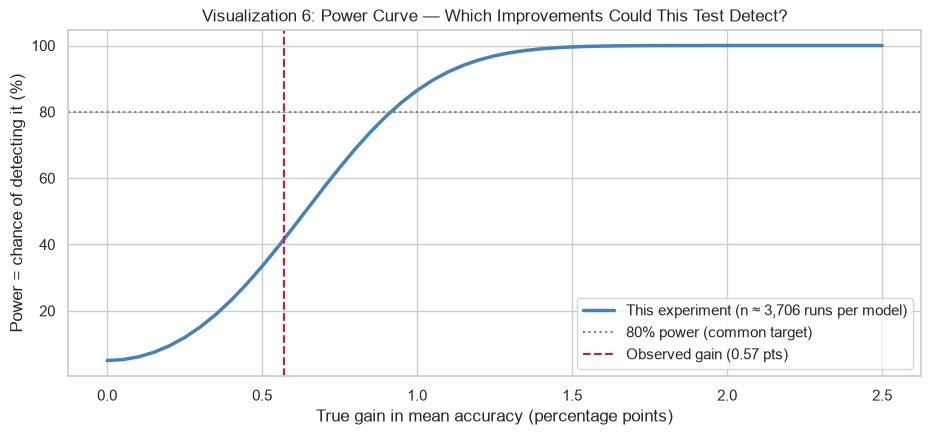

In [18]:
# --- Power of the C vs. A test for different true gains, with this experiment's sample sizes ---
n_c, n_a = len(acc[CANDIDATE]), len(acc[BASELINE])
gains = np.linspace(0, 2.5, 51)                                    # true gains in percentage points
powers = [power_calc.power(effect_size=g / 100 / sd_acc, nobs1=n_c, ratio=n_a / n_c, alpha=ALPHA) for g in gains]
power_obs = power_calc.power(effect_size=abs(main["difference"]) / sd_acc, nobs1=n_c, ratio=n_a / n_c, alpha=ALPHA)
power_1pt = power_calc.power(effect_size=0.01 / sd_acc, nobs1=n_c, ratio=n_a / n_c, alpha=ALPHA)
print(f"Power to detect a true gain equal to the observed {main['difference'] * 100:.2f} points: {power_obs:.1%} "
      f"(Type II error risk β = {1 - power_obs:.1%})")
print(f"Power to detect a true gain of 1.0 point: {power_1pt:.1%} (β = {1 - power_1pt:.1%})")

# --- Visualization 6: power curve ---
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(gains, np.array(powers) * 100, color="steelblue", lw=2.5, label=f"This experiment (n ≈ {n_c:,} runs per model)")
ax.axhline(80, color="gray", linestyle=":", label="80% power (common target)")
ax.axvline(main["difference"] * 100, color="crimson", linestyle="--", label=f"Observed gain ({main['difference'] * 100:.2f} pts)")
ax.set_xlabel("True gain in mean accuracy (percentage points)")
ax.set_ylabel("Power = chance of detecting it (%)")
ax.set_title("Visualization 6: Power Curve — Which Improvements Could This Test Detect?")
ax.legend()
plt.show()

**Type I error (false positive: promoting a model that is not better).**
- When the single comparison of C vs. A is **planned in advance**, the simulated false-positive rate is **5.4%**, matching the chosen α = 5%. The test is well calibrated.
- When an analyst runs **all six pairwise tests** and reports any significant one, the false-positive rate rises to about **20%**. That is one in five experiments "finding" an improvement that does not exist. The simple formula 1 − 0.95⁶ = 26.5% overstates it slightly because the six tests share data, so they are not independent. This is why the ANOVA was followed by **Tukey's HSD**, and why the final decision should not rest on picking the best of several models.
- **Credibility of this result:** because we failed to reject H₀, a Type I error is **not possible** here. The risk is the opposite one.

**Type II error (false negative: missing a model that is better).**
- If Model C's true gain really were **0.57 points**, this experiment would detect it only about **42% of the time** (Visualization 6), so the risk of a Type II error would be about **58%**. In that sense, "not significant" is a **weak** conclusion for a gain this small.
- For gains that **matter in practice**, the test is strong. It has **86.5% power to detect a 1-point gain**, so a Type II error is unlikely for any improvement worth deploying.

**Other sources of error.**
- **Simulated data:** the lack of any learning curve suggests the data is synthetic, so the results describe this dataset, not real model training.
- **Dependence:** if real evaluations came from the same training runs, they would be correlated. The true standard error would then be larger, and the p-values here would be **too small**, not too large.
- **Choice of metric:** accuracy and F1 rank the models differently, so conclusions can depend on which metric is chosen. The metric should be fixed in advance.

## 14. Model Improvement

### 14.1 From "not significant" to "practically equivalent": the TOST equivalence test

A standard *t*-test can never show that two models are the **same**: "fail to reject H₀" only means the evidence for a difference is weak. An **equivalence test** (TOST, two one-sided tests) flips the question (Lakens, 2017). It sets a margin of differences too small to matter, here **±1 percentage point**, and tests:

- H₀: the true difference is **outside** ±1 point (the models are meaningfully different)
- H₁: the true difference is **inside** ±1 point (the models are practically equivalent)

If both one-sided p-values are below 0.05, which happens exactly when the 90% CI for the difference lies inside ±1 point, we can conclude the models are **practically equivalent**.

In [19]:
# --- TOST equivalence test for each candidate vs. the baseline, with a ±1 point margin ---
MARGIN = 0.01
tost_rows = []
for m in ("Model_B", "Model_C", "Model_D"):
    p_tost, lower_test, upper_test = ttost_ind(acc[m], acc[BASELINE], -MARGIN, MARGIN, usevar="unequal")
    ci90 = welch_test(acc[m], acc[BASELINE], conf=0.90)
    tost_rows.append({"comparison": f"{m} − {BASELINE}", "difference (pts)": ci90["difference"] * 100,
                      "90% CI (pts)": f"{ci90['CI lower'] * 100:+.2f} to {ci90['CI upper'] * 100:+.2f}",
                      "TOST p-value": p_tost,
                      "conclusion": "Practically equivalent (within ±1 pt)" if p_tost < ALPHA else "Cannot claim equivalence"})
pd.DataFrame(tost_rows).set_index("comparison")

,difference (pts),90% CI (pts),TOST p-value,conclusion
comparison,,,,
Model_B − Model_A,0.1999,-0.34 to +0.74,0.0071,Practically equivalent (within ±1 pt)
Model_C − Model_A,0.5713,+0.03 to +1.11,0.0953,Cannot claim equivalence
Model_D − Model_A,-0.4025,-0.95 to +0.14,0.0352,Practically equivalent (within ±1 pt)


**Equivalence results.**
- **Model B and Model D are practically equivalent to the baseline.** Their 90% CIs lie entirely inside ±1 point (TOST p = 0.007 and 0.035). We can now state positively that they perform the same as Model A for practical purposes, which the ordinary *t*-test could not do.
- **Model C cannot be declared equivalent** (TOST p = 0.095). Its 90% CI (+0.03 to +1.11 points) reaches just past the +1 point margin. So Model C is **neither significantly better** (Section 9) **nor provably equivalent**. A gain of up to about 1 point cannot be ruled out.
- **What this means for the team:** Model C's result is **inconclusive**, not negative. The right next step is a **better-designed experiment** (Section 14.2), for example a paired comparison on the same test sets, before deciding whether to deploy it.

### 14.2 Other improvements to the experiment

- **Paired design.** Evaluate both models on the **same** test sets, random seeds, and epochs, and test the *paired* differences. Removing the variation between test sets makes the standard error much smaller, so real improvements are easier to detect with fewer runs (Dietterich, 1998).
- **Pre-registration.** Write down the hypothesis, metric, α, and minimum worthwhile gain *before* seeing results (Section 8), so the test cannot be tuned after the fact.
- **Plan the sample size.** Use the power analysis in Section 8 to choose the number of runs needed for the smallest gain worth deploying.
- **Correct for multiple comparisons** whenever several models or metrics are compared, as Tukey's HSD does.
- **Report effect sizes and confidence intervals**, not just p-values.

## 15. Final Conclusion

| Analysis | Key finding |
|---|---|
| Research question | Does the new Model C have higher mean accuracy than the baseline Model A? |
| Main test (Welch two-sample t-test) | t = 1.74, df ≈ 7,519, **p = 0.081**, 95% CI for μ_C − μ_A = **−0.07 to +1.21 points** |
| Decision | **Fail to reject H₀** at α = 0.05: no statistically significant improvement |
| Effect size | +0.57 points, Cohen's d = 0.04 (negligible) |
| One-sample test vs. 75% target | p = 0.82: Model C is not shown to beat the target |
| ANOVA + Tukey (4 models) | ANOVA p = 0.027, but only C vs. D differs (adjusted p = 0.016); C vs. A adjusted p = 0.30 |
| Robustness | Permutation (p = 0.083), bootstrap CI, and Mann–Whitney (p = 0.086) all agree |
| Type I error | 5.4% for one pre-planned test, about 20% when choosing the best of six comparisons |
| Type II error / power | 42% power for the observed 0.57-point gain, 86.5% for a 1-point gain |
| Equivalence (TOST, ±1 point) | B and D are practically equivalent to A; C is inconclusive |

**Conclusion.** The new Model C's 0.57-point accuracy advantage over the baseline is **not statistically significant**. It is small compared with the run-to-run variation, it disappears after correcting for comparing several models, it does not appear in the F1 score, and it can be produced by random shuffling about 8% of the time. The improvement is **most likely due to random variation**. Based on this evidence, Model C should **not** be promoted on accuracy alone.

**Implications for AI model evaluation.** Small accuracy differences between models are common and often meaningless. Before claiming that a new model is better, a team should fix the hypothesis, metric, and α in advance, plan enough evaluation runs with a power analysis, correct for multiple comparisons, report effect sizes and confidence intervals alongside p-values, and use equivalence tests when the goal is to show that models perform the same. These steps protect against both errors: promoting models that are not really better (Type I), and missing ones that are (Type II).

## 16. References

Cohen, J. (1988). *Statistical power analysis for the behavioral sciences* (2nd ed.). Lawrence Erlbaum Associates. https://doi.org/10.4324/9780203771587

Dietterich, T. G. (1998). Approximate statistical tests for comparing supervised classification learning algorithms. *Neural Computation, 10*(7), 1895–1923. https://doi.org/10.1162/089976698300017197

Grand Canyon University. (n.d.-a). *AIT-530 Topic 4 dataset* [Data set]. AIT-530 course resources.

Grand Canyon University. (n.d.-b). *Business case: Yulu – hypothesis testing* [Course resource]. AIT-530 Topic 4 resources.

Lakens, D. (2017). Equivalence tests: A practical primer for t tests, correlations, and meta-analyses. *Social Psychological and Personality Science, 8*(4), 355–362. https://doi.org/10.1177/1948550617697177

Mann, H. B., & Whitney, D. R. (1947). On a test of whether one of two random variables is stochastically larger than the other. *The Annals of Mathematical Statistics, 18*(1), 50–60. https://doi.org/10.1214/aoms/1177730491

Seabold, S., & Perktold, J. (2010). statsmodels: Econometric and statistical modeling with Python. In *Proceedings of the 9th Python in Science Conference* (pp. 92–96). https://doi.org/10.25080/Majora-92bf1922-011

Tukey, J. W. (1949). Comparing individual means in the analysis of variance. *Biometrics, 5*(2), 99–114. https://doi.org/10.2307/3001913

Virtanen, P., Gommers, R., Oliphant, T. E., Haberland, M., Reddy, T., Cournapeau, D., Burovski, E., Peterson, P., Weckesser, W., Bright, J., van der Walt, S. J., Brett, M., Wilson, J., Millman, K. J., Mayorov, N., Nelson, A. R. J., Jones, E., Kern, R., Larson, E., … SciPy 1.0 Contributors. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. *Nature Methods, 17*(3), 261–272. https://doi.org/10.1038/s41592-019-0686-2

Wasserstein, R. L., & Lazar, N. A. (2016). The ASA statement on p-values: Context, process, and purpose. *The American Statistician, 70*(2), 129–133. https://doi.org/10.1080/00031305.2016.1154108

Welch, B. L. (1947). The generalization of "Student's" problem when several different population variances are involved. *Biometrika, 34*(1–2), 28–35. https://doi.org/10.1093/biomet/34.1-2.28